In [22]:
import scanpy as sc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from matplotlib.lines import Line2D
from matplotlib import colors as mcolors
import warnings
warnings.filterwarnings("ignore")


def plot_spatial_compact_fast(
    ad,
    color="leiden_2",
    groupby="sample_id",
    spot_size=8,
    cols=3,
    height=8,
    legend_col_width=1.2,
    palette=None,            # dict {cat:"#hex"} or list
    rasterized=True,         # big speedup for vectors/PDFs
    invert_y=True,           # match Scanpy orientation
    dpi=120,                 # lower dpi → faster
):
    # ----- 0) Preconditions -----
    if "spatial" not in ad.obsm:
        raise ValueError("ad.obsm['spatial'] is required.")

    coords = np.asarray(ad.obsm["spatial"])[:, :2]
    cats = ad.obs[color].astype("category")
    cat_names = cats.cat.categories
    cat_codes = cats.cat.codes.to_numpy()  # -1 for NaN

    # ----- 1) Build shared palette (RGBA array) -----
    if isinstance(palette, dict):
        col_list = [palette[c] for c in cat_names]
    elif isinstance(palette, (list, tuple)):
        if len(palette) < len(cat_names):
            raise ValueError("Palette shorter than number of categories.")
        col_list = list(palette)[:len(cat_names)]
    elif f"{color}_colors" in ad.uns:
        col_list = list(ad.uns[f"{color}_colors"])
        if len(col_list) != len(cat_names):
            raise ValueError(f"{color}_colors length != categories.")
    else:
        base = getattr(getattr(__import__("scanpy").pl.palettes, "default_64", []), "__iter__", None)
        base = list(__import__("scanpy").pl.palettes.default_64
                    if hasattr(__import__("scanpy").pl.palettes, "default_64")
                    else __import__("scanpy").pl.palettes.default_102)
        reps = int(np.ceil(len(cat_names) / len(base)))
        col_list = (base * reps)[:len(cat_names)]

    # store for consistency elsewhere
    ad.uns[f"{color}_colors"] = col_list

    # convert to RGBA float array for fast indexing
    rgba = np.array([mcolors.to_rgba(c) for c in col_list], dtype=float)
    # map codes -> rgba; handle -1 (NaN) as transparent
    colors_arr = np.empty((cat_codes.size, 4), dtype=float)
    colors_arr[cat_codes >= 0] = rgba[cat_codes[cat_codes >= 0]]
    colors_arr[cat_codes < 0] = (0, 0, 0, 0)

    # ----- 2) Precompute group indices (no per-iteration masks) -----
    gvals = ad.obs[groupby].astype(str).to_numpy()
    uniq_groups, gcodes = np.unique(gvals, return_inverse=True)
    # list of index arrays per group
    group_indices = [np.flatnonzero(gcodes == gi) for gi in range(len(uniq_groups))]

    # ----- 3) Figure layout -----
    n = len(uniq_groups)
    rows = int(np.ceil(n / cols))
    panel_w = height * cols * 0.6 / rows
    fig_w = panel_w + legend_col_width

    plt.ioff()  # speed: disable interactive redraws
    fig = plt.figure(figsize=(fig_w, height), dpi=dpi, constrained_layout=False)
    gs = GridSpec(
        rows, cols + 1, figure=fig,
        width_ratios=[1]*cols + [legend_col_width / (fig_w - legend_col_width)],
        wspace=0.02, hspace=0.02
    )

    # ----- 4) Panels (fast scatter) -----
    for i, sid in enumerate(uniq_groups):
        r, c = divmod(i, cols)
        ax = fig.add_subplot(gs[r, c])

        idx = group_indices[i]
        if idx.size:
            xy = coords[idx]
            # note: turn off edgecolor & use rasterized for speed
            sca = ax.scatter(
                xy[:, 0], xy[:, 1],
                c=colors_arr[idx],
                s=spot_size,
                marker='o',
                linewidths=0,
                rasterized=rasterized
            )
        ax.set_title(str(sid), fontsize=9, pad=2)
        ax.set_aspect("equal")
        if invert_y:
            ax.invert_yaxis()
        ax.set_axis_off()

    # blank unused
    for j in range(n, rows * cols):
        r, c = divmod(j, cols)
        fig.add_subplot(gs[r, c]).axis("off")

    # ----- 5) Legend (single, shared) -----
    ax_leg = fig.add_subplot(gs[:, -1])
    ax_leg.axis("off")
    handles = [
        Line2D([0], [0], marker='o', color='w',
               markerfacecolor=col_list[k], markersize=7, label=str(cat))
        for k, cat in enumerate(cat_names)
    ]
    ax_leg.legend(handles=handles, title=color, frameon=False, loc="center left")

    fig.subplots_adjust(left=0.01, right=0.98, top=0.98, bottom=0.02, wspace=0.02, hspace=0.02)
    plt.ion()  # ✅ correct
    plt.show()

In [4]:
data_dir = '/date/gcb/gcb_CML/oligo-mtDSB/data/'

In [2]:
adata = sc.read_h5ad('/date/gcb/gcb_CML/oligo-mtDSB/results/rbd_runs/--data-base/rbd_annotated_monod.h5ad')

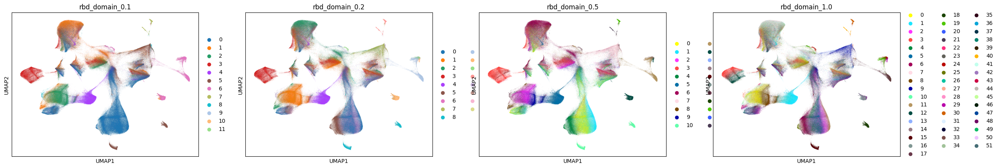

In [11]:
sc.pl.umap(adata_psedob, color = ['rbd_domain_0.1','rbd_domain_0.2','rbd_domain_0.5','rbd_domain_1.0'])

Plotting rbd_domain_0.1 …


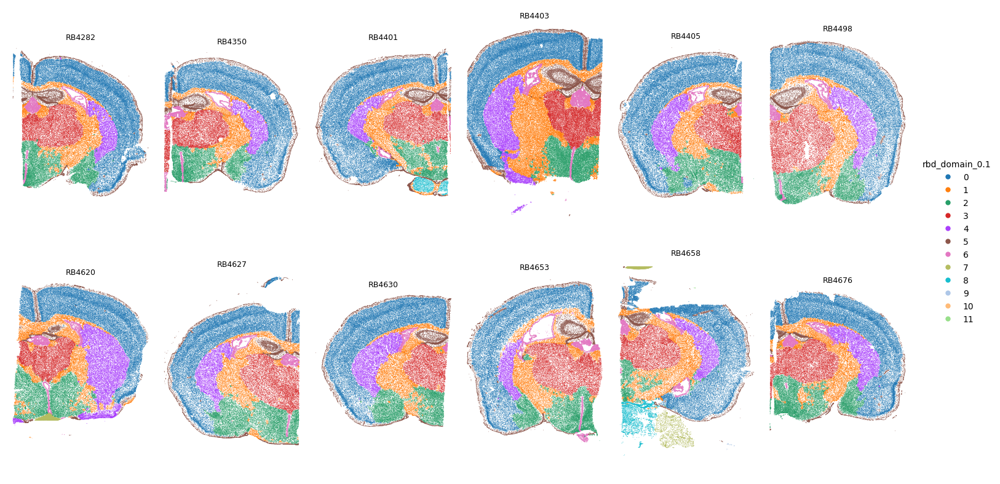

Plotting rbd_domain_0.2 …


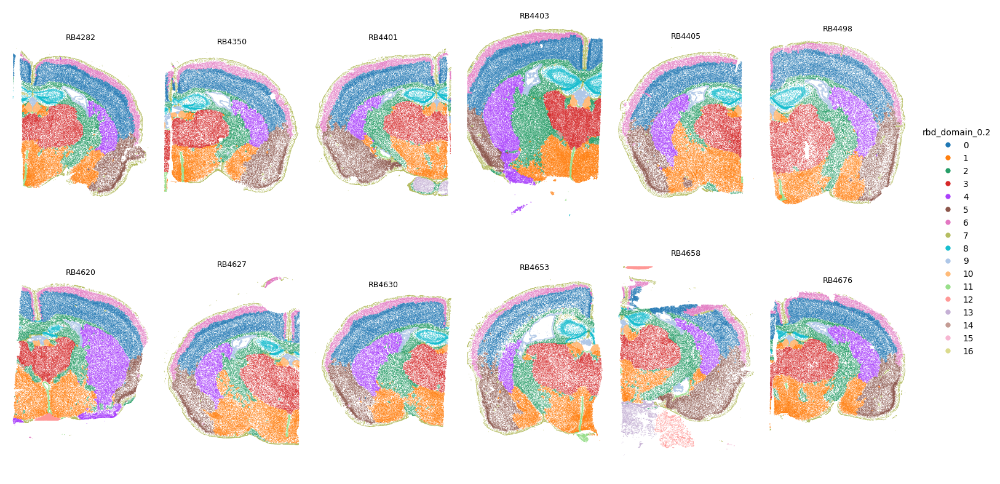

Plotting rbd_domain_0.5 …


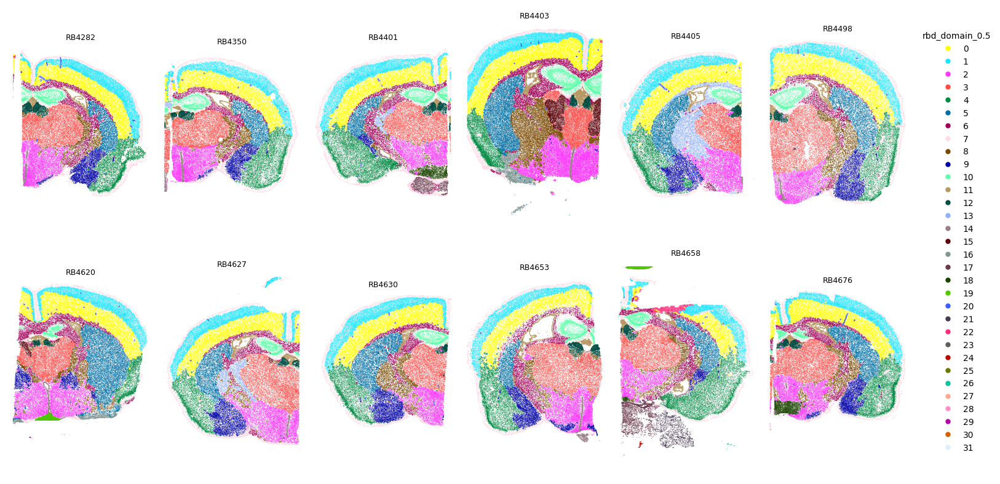

Plotting rbd_domain_1.0 …


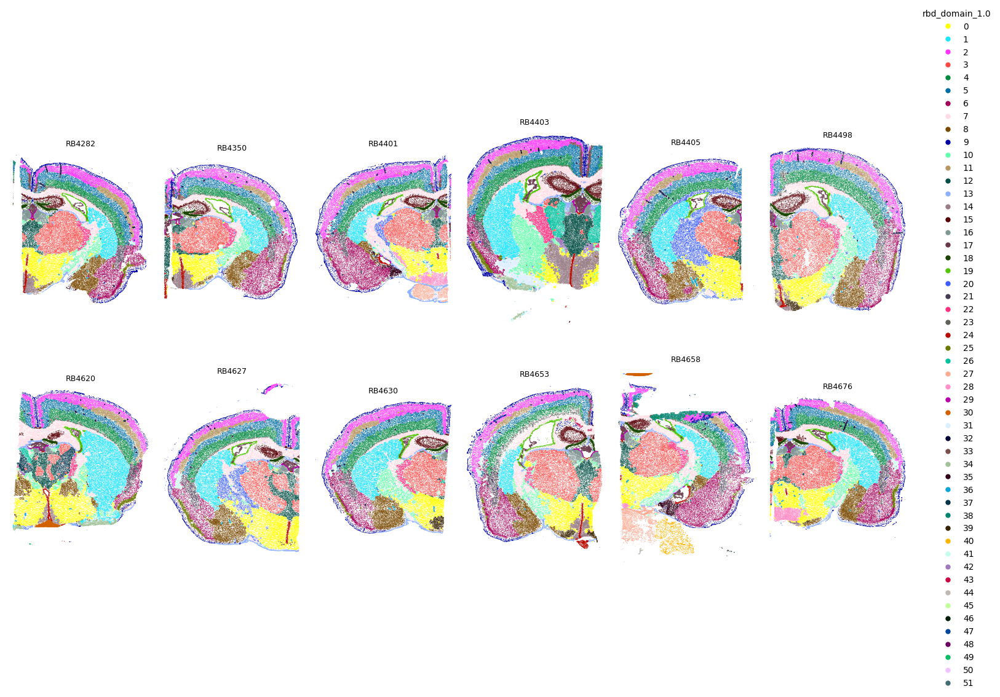

In [21]:
for domain in ['rbd_domain_0.1', 'rbd_domain_0.2', 'rbd_domain_0.5', 'rbd_domain_1.0']:
    if domain in adata.obs.columns:
        print(f"Plotting {domain} …")
        plot_spatial_compact_fast(
            adata,
            color=domain,
            groupby="sample_id",
            spot_size=0.3,
            cols=6,
            height=8,
            legend_col_width=1.0,
            rasterized=True,   # big speedup for large data
            dpi=100             # lower = faster preview
        )
    else:
        print(f"Skipping {domain} — not in adata.obs")

In [24]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from matplotlib.lines import Line2D
from matplotlib import colors as mcolors

def plot_spatial_highlight(
    ad,
    color,                      # obs column with categories
    highlight,                  # one category to highlight
    groupby="sample_id",
    spot_size=12,
    cols=3,
    height=7,
    flip_y=True,
    fix_limits=True,            # same axes for all panels
    base_color="#B0B0B0",       # de-emphasized others
    base_alpha=0.15,
    palette=None,               # dict {cat:"#hex"} or list; if None try ad.uns[f"{color}_colors"]
    rasterized=True,
    dpi=120,
):
    if "spatial" not in ad.obsm:
        raise ValueError("ad.obsm['spatial'] is required.")
    coords = np.asarray(ad.obsm["spatial"])[:, :2]

    # categories & palette
    cats = ad.obs[color].astype("category")
    cat_names = list(cats.cat.categories)
    if isinstance(palette, dict):
        col_list = [palette.get(c, "#377eb8") for c in cat_names]
    elif isinstance(palette, (list, tuple)) and len(palette) >= len(cat_names):
        col_list = list(palette)[:len(cat_names)]
    elif f"{color}_colors" in ad.uns and len(ad.uns[f"{color}_colors"]) == len(cat_names):
        col_list = list(ad.uns[f"{color}_colors"])
    else:
        # fallback: simple cycle
        from scanpy.pl import palettes
        base = palettes.default_64 if hasattr(palettes, "default_64") else palettes.default_102
        reps = int(np.ceil(len(cat_names) / len(base)))
        col_list = (base * reps)[:len(cat_names)]

    # pick highlight color
    if highlight not in cat_names:
        raise ValueError(f"'{highlight}' not found in ad.obs['{color}'] categories.")
    h_idx = cat_names.index(highlight)
    hl_hex = col_list[h_idx]
    hl_rgba = np.array(mcolors.to_rgba(hl_hex), float)

    # precompute color array: highlight vs base
    base_rgba = np.array(mcolors.to_rgba(base_color), float)
    base_rgba[3] = base_alpha

    cat_codes = cats.cat.codes.to_numpy()  # -1 for NaN
    is_highlight = (cat_codes == h_idx)
    # initialize all as base, then overwrite highlights
    colors_arr = np.empty((cat_codes.size, 4), dtype=float)
    colors_arr[:] = base_rgba
    colors_arr[is_highlight] = hl_rgba
    # transparent for NaN
    colors_arr[cat_codes < 0] = (0, 0, 0, 0)

    # group indices (preserve observed order if possible)
    gseries = ad.obs[groupby]
    if pd.api.types.is_categorical_dtype(gseries):
        uniq_groups = list(gseries.cat.categories)
        # keep only those present
        uniq_groups = [g for g in uniq_groups if (gseries == g).any()]
        gcodes = pd.Categorical(gseries, categories=uniq_groups, ordered=True).codes
    else:
        uniq_groups = list(pd.unique(gseries))  # preserves first-appearance order
        mapping = {g:i for i,g in enumerate(uniq_groups)}
        gcodes = gseries.map(mapping).to_numpy()
    group_indices = [np.flatnonzero(gcodes == i) for i in range(len(uniq_groups))]

    # common limits (global) if requested
    if fix_limits:
        x_min, y_min = coords.min(axis=0)
        x_max, y_max = coords.max(axis=0)

    # layout
    n = len(uniq_groups)
    rows = int(np.ceil(n / cols))
    panel_w = height * cols * 0.6 / rows
    fig_w = panel_w  # legend-free; keep compact
    plt.ioff()
    fig = plt.figure(figsize=(fig_w, height), dpi=dpi, constrained_layout=False)
    gs = GridSpec(rows, cols, figure=fig, wspace=0.02, hspace=0.02)

    # panels
    axes = []
    for i, sid in enumerate(uniq_groups):
        r, c = divmod(i, cols)
        ax = fig.add_subplot(gs[r, c])
        idx = group_indices[i]
        if idx.size:
            xy = coords[idx]
            ax.scatter(
                xy[:, 0], xy[:, 1],
                c=colors_arr[idx],
                s=spot_size,
                marker='o',
                linewidths=0,
                rasterized=rasterized
            )
        ax.set_title(f"{sid} — {highlight}", fontsize=9, pad=2)
        ax.set_aspect("equal")
        if flip_y:
            ax.invert_yaxis()
        if fix_limits:
            ax.set_xlim(x_min, x_max)
            ax.set_ylim(y_max, y_min) if flip_y else ax.set_ylim(y_min, y_max)
        ax.set_axis_off()
        axes.append(ax)

    # blank unused
    for j in range(n, rows * cols):
        r, c = divmod(j, cols)
        fig.add_subplot(gs[r, c]).axis("off")

    plt.ion()
    return fig, axes

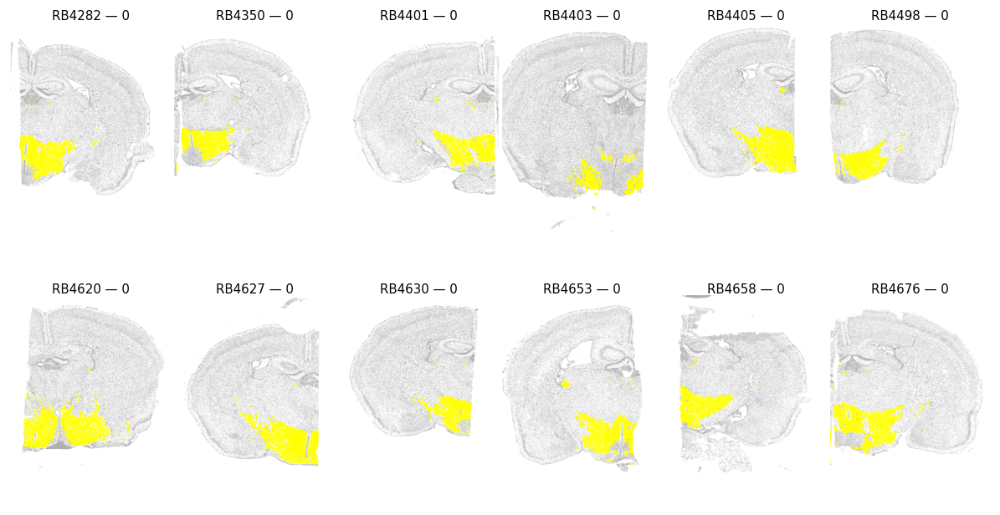

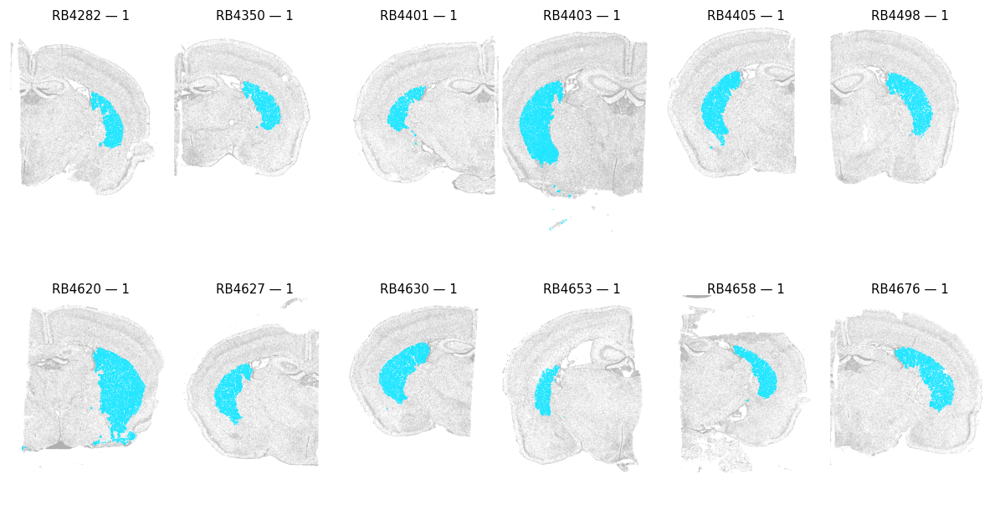

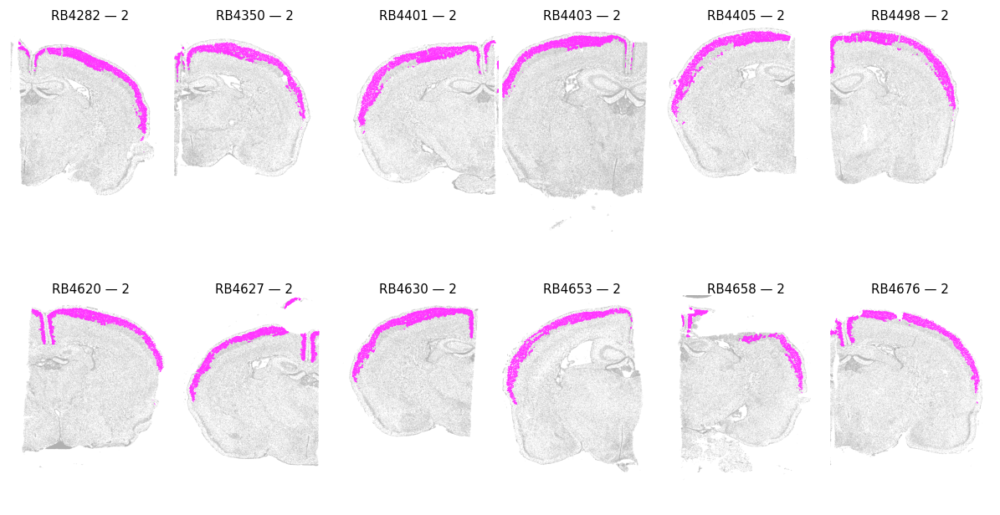

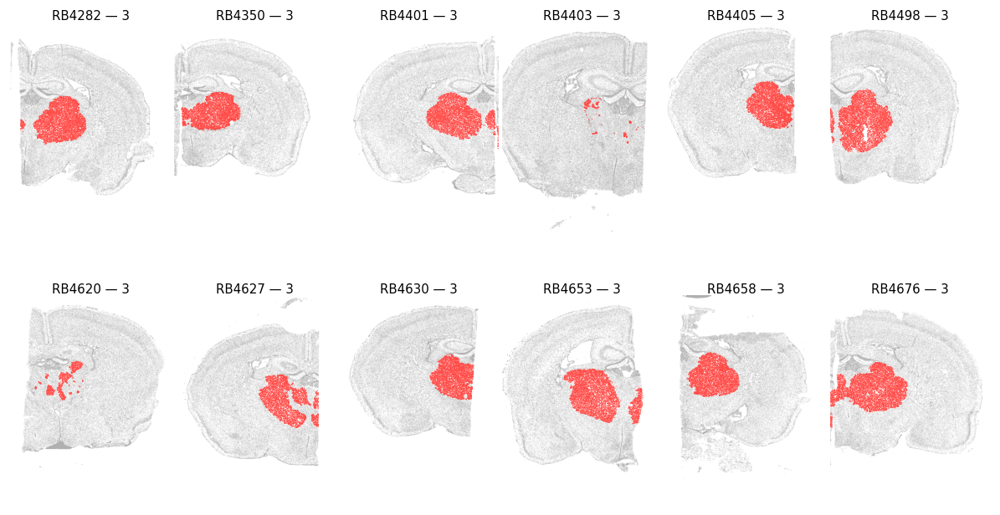

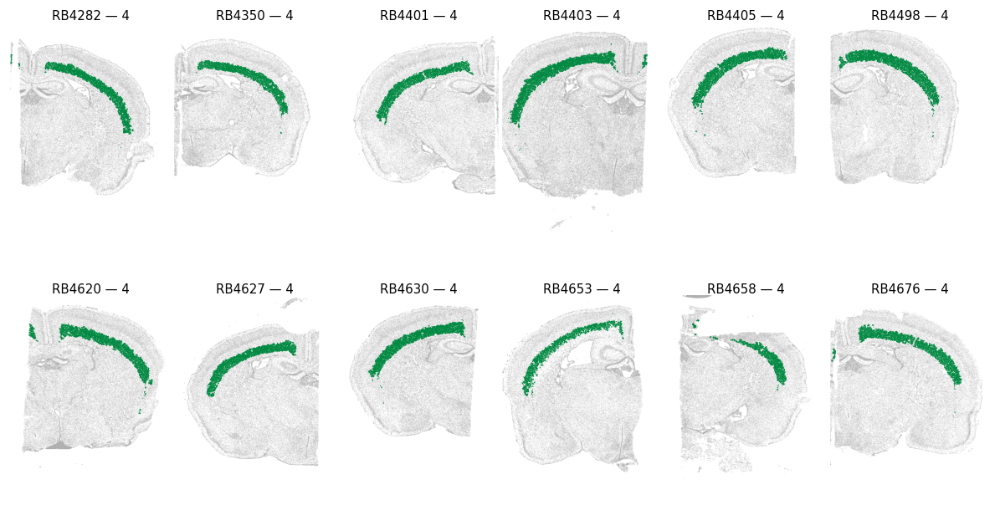

...

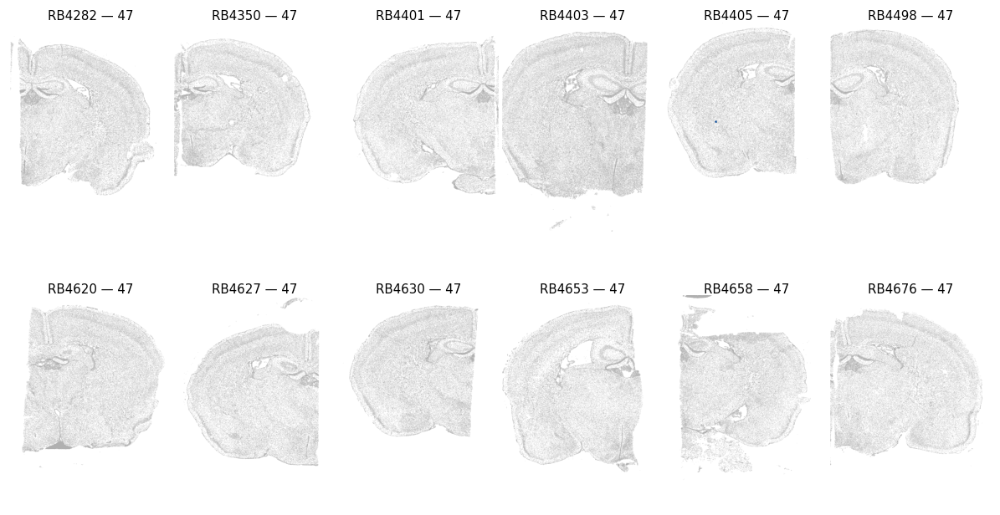

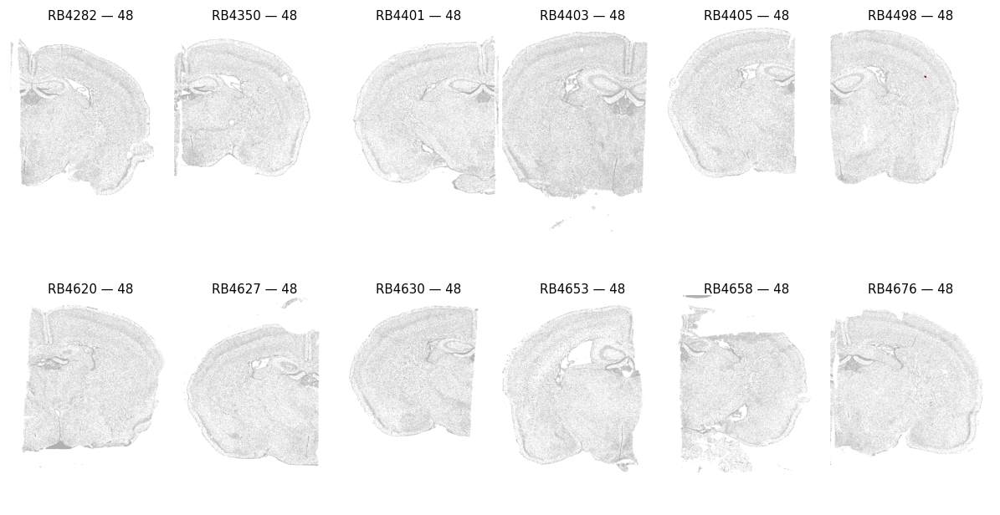

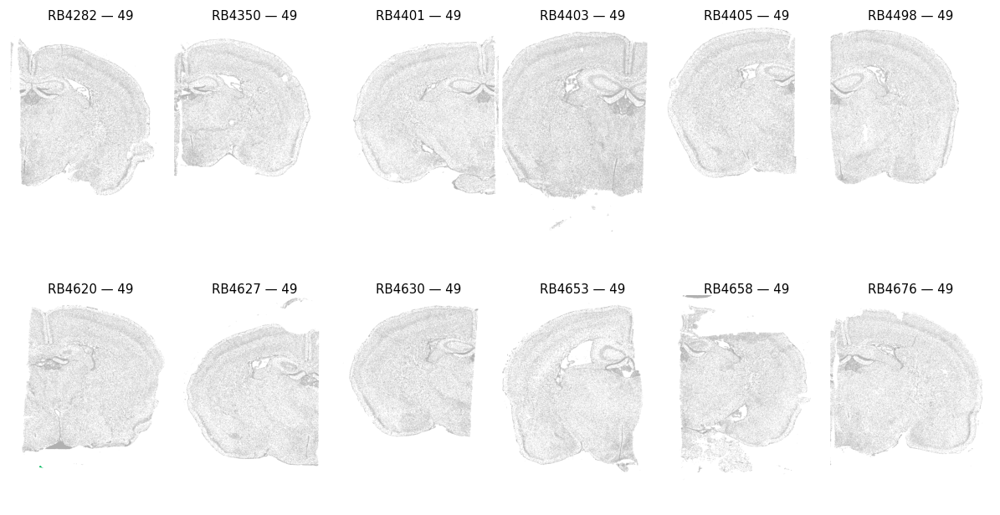

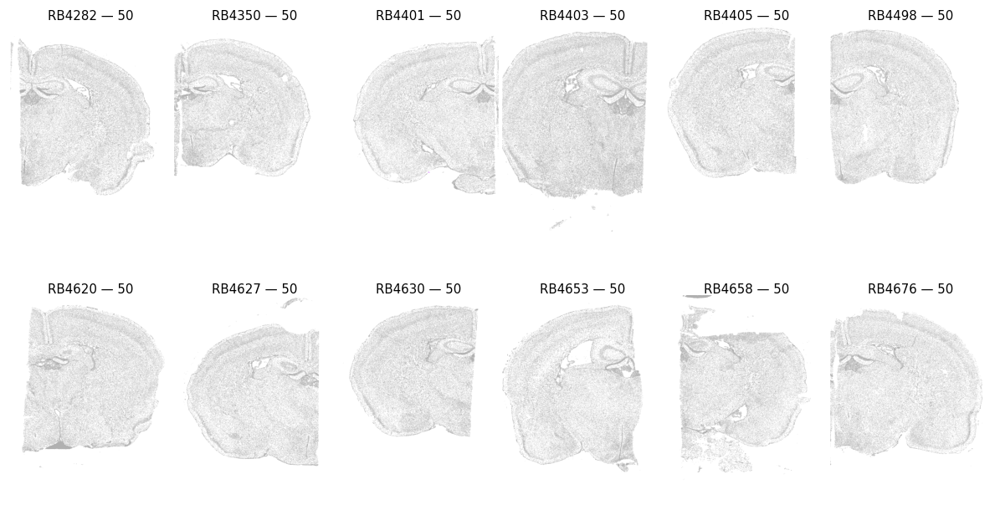

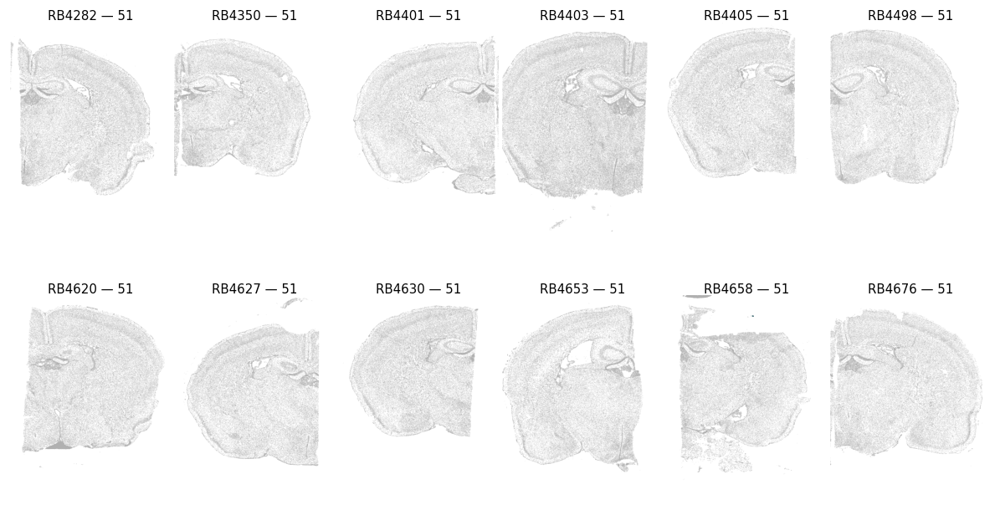

In [29]:
domain_key = "rbd_domain_1.0"

for cl in adata.obs[domain_key].astype("category").cat.categories:
    fig, _ = plot_spatial_highlight(
        adata,
        color=domain_key,
        highlight=cl,
        groupby="sample_id",
        spot_size=0.3,
        cols=6,
        height=7,
        flip_y=True,
        fix_limits=True
    )
    plt.show()
    # fig.savefig(os.path.join(outdir, f"{domain_key}_cluster_{cl}.png"), dpi=300, bbox_inches="tight")
    # plt.close(fig)

In [32]:
d = {
    '0': 'Hypothalamus',
    '1': 'Caudoputamen',
    '2': 'Cortex I',
    '3': 'Thalamus I',
    '4': 'Cortex II',
    '5': 'Cortex III',
    '6': 'Olfactory areas',
    '7': 'Fiber tracts I',
    '8': 'Striatum ventral region',
    '9': 'Meningeal border/glia limitans',
    '10': 'Palladium',
    '11': 'Cortex IV',
    '12': 'Thalamus I', # II
    '13': 'Meningeal border/glia limitans', # dont really know about this one
    '14': 'Hypothalamus', # II
    '15': 'Hippocampal formation',
    '16': 'Epithalamus',
    '17': 'Ventricular system',
    '18': 'Dentate gyrus',
    '19': 'Lateral ventricle',
    '20': 'Fiber tracts II',
    '21': 'Cortical subplate',
    '22': 'Corticospinal tract',
    '23': 'Cortex V',
    '24': 'Ventricular system',
    '25': 'Piriform area',
    '26': 'Thalamus II',
    '27': 'Uknown I',
    '28': 'Hypothalamus',
    '29': 'Ventricular system',
    '30': 'Unknown II',
    '31': 'Olfactory areas',
    '32': 'Cortical vasculature',
    '33': 'Retrosplenial area',
    '34': 'Unknown III',
    '35': 'Striatum ventral region',
    '36': 'Parenchymal vasculature',
    '37': 'Thalamus III',
    '38': 'Unknown III',
    '39': 'Hypothalamus',
    '40': 'Unknown IV',
    '41': 'Cortex VI',
    '42': 'Thalamus IV',
    '43': 'Cortex V',
    '44': 'Unknown',
    '45': 'Unknown',
    '46': 'Unknown',
    '47': 'Unknown',
    '48': 'Unknown',
    '49': 'Unknown',
    '50': 'Unknown',
    '51': 'Unknown'
}

In [33]:
adata.obs['RBD_compartment'] = adata.obs['rbd_domain_1.0'].map(d)

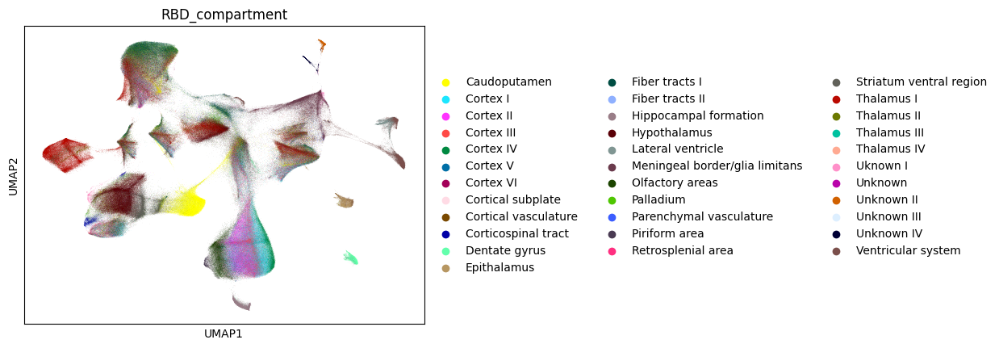

In [34]:
sc.pl.umap(adata, color = 'RBD_compartment')

Plotting RBD_compartment …


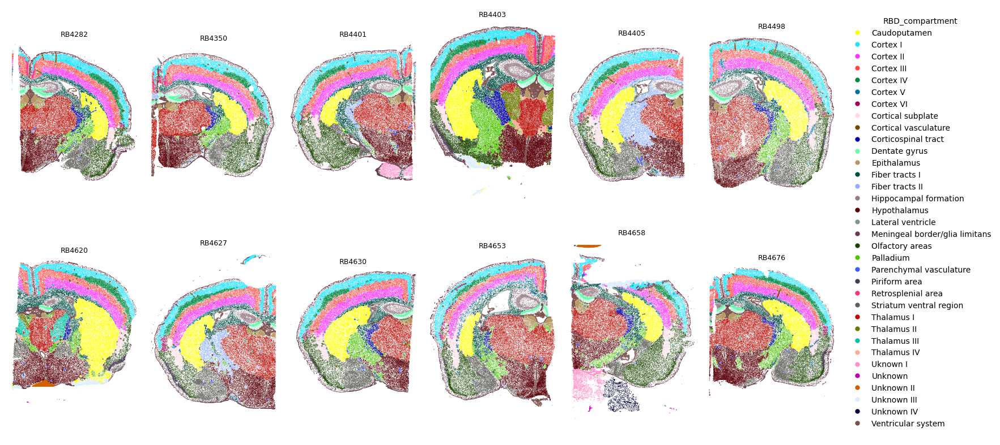

In [35]:
for domain in ['RBD_compartment']:
    if domain in adata.obs.columns:
        print(f"Plotting {domain} …")
        plot_spatial_compact_fast(
            adata,
            color=domain,
            groupby="sample_id",
            spot_size=0.3,
            cols=6,
            height=8,
            legend_col_width=1.0,
            rasterized=True,   # big speedup for large data
            dpi=100             # lower = faster preview
        )
    else:
        print(f"Skipping {domain} — not in adata.obs")

In [37]:
simplified_map = {
    'Cortex I': 'Cortex',
    'Cortex II': 'Cortex',
    'Cortex III': 'Cortex',
    'Cortex IV': 'Cortex',
    'Cortex V': 'Cortex',
    'Cortex VI': 'Cortex',

    'Unknown I': 'Unknown',
    'Unknown II': 'Unknown',
    'Unknown III': 'Unknown',
    'Unknown IV': 'Unknown',
    'Uknown I': 'Unknown',  # typo handled

    'Meningeal border/glia limitans': 'Meningeal border/glia limitans',
    'Retrosplenial area': 'Cortex',
    'Fiber tracts I': 'Fiber tracts',
    'Fiber tracts II': 'Fiber tracts',
    'Cortical vasculature': 'Vasculature',
    'Lateral ventricle': 'Ventricular system',
    'Ventricular system': 'Ventricular system',
    'Caudoputamen': 'Striatum',
    'Hippocampal formation': 'Hippocampus',
    'Dentate gyrus': 'Hippocampus',
    'Epithalamus': 'Thalamus',
    'Striatum ventral region': 'Striatum',
    'Olfactory areas': 'Olfactory areas',
    'Piriform area': 'Olfactory areas',
    'Parenchymal vasculature': 'Vasculature',
    'Thalamus I': 'Thalamus',
    'Thalamus II': 'Thalamus',
    'Thalamus III': 'Thalamus',
    'Thalamus IV': 'Thalamus',
    'Hypothalamus': 'Hypothalamus',
    'Palladium': 'Pallidum',
    'Cortical subplate': 'Cortex',
    'Corticospinal tract': 'Fiber tracts',
    'Unknown': 'Unknown'
}
adata.obs['RBD_compartment_simplified'] = adata.obs.RBD_compartment.map(simplified_map)

In [38]:
adata.write('/date/gcb/gcb_CML/oligo-mtDSB/results/rbd_runs/--data-base/rbd_annotated_monod_annotated.h5ad')